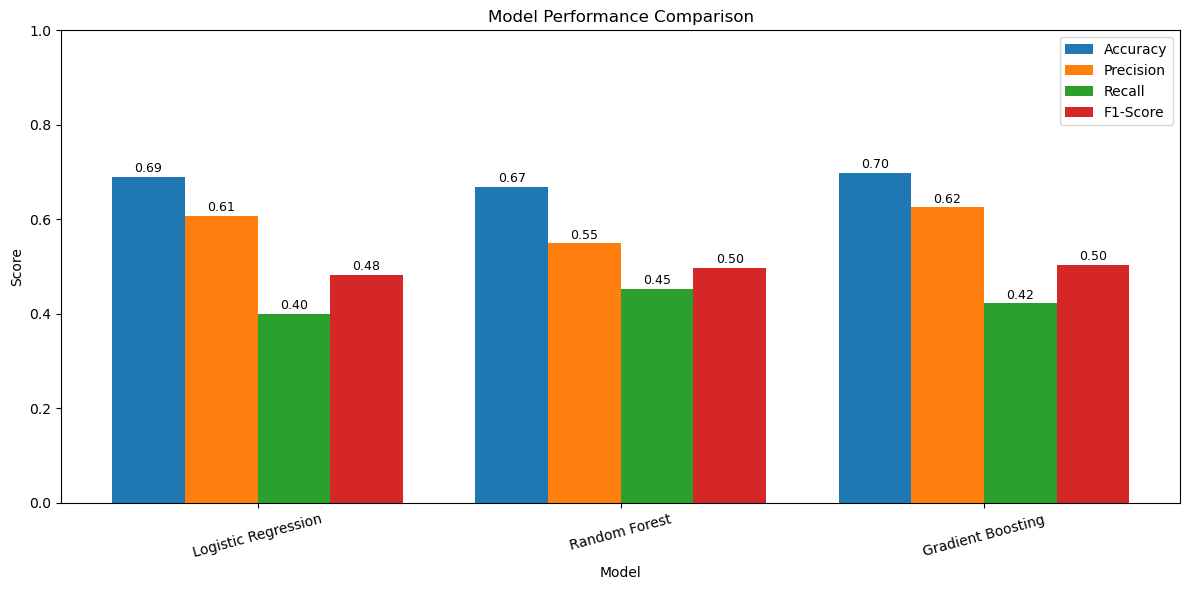

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data
models = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
accuracy = [0.690, 0.668, 0.699]
precision = [0.608, 0.549, 0.625]
recall = [0.400, 0.453, 0.422]
f1 = [0.483, 0.497, 0.504]

# X positions
x = np.arange(len(models))
width = 0.2

# Create figure
plt.figure(figsize=(12, 6))

# Bars
plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
plt.bar(x - 0.5*width, precision, width, label='Precision')
plt.bar(x + 0.5*width, recall, width, label='Recall')
plt.bar(x + 1.5*width, f1, width, label='F1-Score')

# Labels and title
plt.xlabel('Model')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x, models, rotation=15)
plt.ylim(0, 1.0)
plt.legend()

# Add value labels on bars
for i, values in enumerate([accuracy, precision, recall, f1]):
    for j, v in enumerate(values):
        plt.text(
            x[j] + (i - 1.5) * width,
            v + 0.01,
            f"{v:.2f}",
            ha='center',
            fontsize=9
        )

plt.tight_layout()
plt.show()

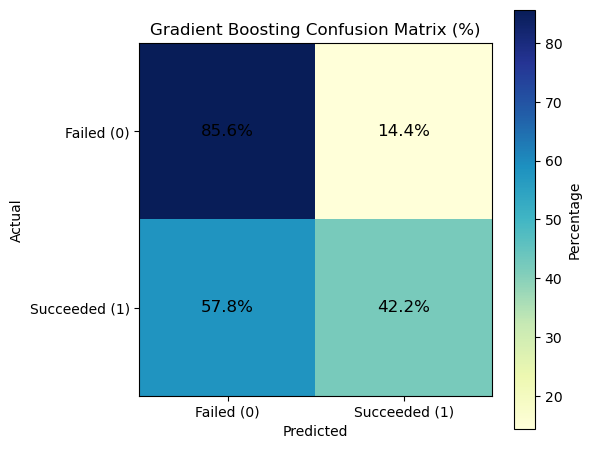

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Confusion matrix (counts)
cm = np.array([
    [40512, 6788],
    [15489, 11302]
])

# Convert to percentages by row
cm_percent = cm / cm.sum(axis=1)[:, np.newaxis] * 100

labels = ["Failed (0)", "Succeeded (1)"]

plt.figure(figsize=(6,5))

# Use a nicer colour map
plt.imshow(cm_percent, cmap="YlGnBu")

plt.colorbar(label="Percentage")

plt.xticks([0,1], labels)
plt.yticks([0,1], labels)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gradient Boosting Confusion Matrix (%)")

# Add percentage text
for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        plt.text(
            j,
            i,
            f"{cm_percent[i,j]:.1f}%",
            ha="center",
            va="center",
            fontsize=12,
            color="black"
        )

plt.tight_layout()

plt.savefig(
    "gradient_boosting_confusion_matrix_percent.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

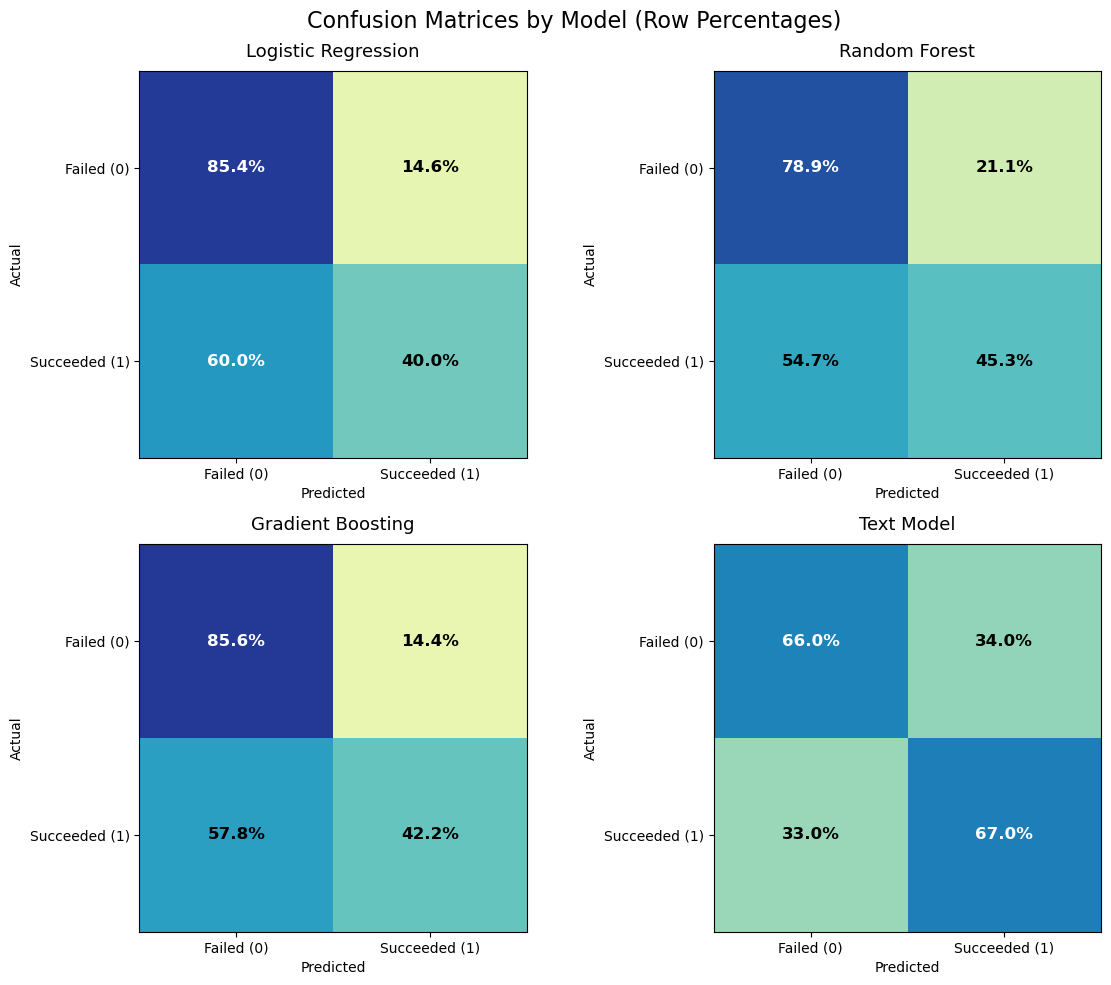

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------
# ROW-NORMALISED CONFUSION MATRICES (%)
# Each row = actual class, sums to 100
# ---------------------------------------------------

matrices_percent = {
    "Logistic Regression": np.array([
        [85.4, 14.6],   # Actual Failed -> Pred Failed, Pred Success
        [60.0, 40.0]    # Actual Success -> Pred Failed, Pred Success
    ]),
    
    "Random Forest": np.array([
        [78.9, 21.1],
        [54.7, 45.3]
    ]),
    
    "Gradient Boosting": np.array([
        [85.6, 14.4],
        [57.8, 42.2]
    ]),
    
    # Based on your reported recalls:
    # Failed recall = 0.66, Success recall = 0.67
    "Text Model": np.array([
        [66.0, 34.0],
        [33.0, 67.0]
    ])
}

labels = ["Failed (0)", "Succeeded (1)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

cmap = "YlGnBu"   # nice clean theme for slides

for ax, (title, cm_percent) in zip(axes, matrices_percent.items()):
    im = ax.imshow(cm_percent, cmap=cmap, vmin=0, vmax=100)
    
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    
    # Write percentages inside cells
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            value = cm_percent[i, j]
            text_color = "white" if value >= 60 else "black"
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center", va="center",
                fontsize=12, color=text_color, fontweight="bold"
            )

# Shared colorbar
# cbar = fig.colorbar(im, ax=axes, fraction=0.046, pad=0.04)
# cbar.set_label("Percentage")

fig.suptitle("Confusion Matrices by Model (Row Percentages)", fontsize=16, y=0.98)
plt.tight_layout()
plt.savefig("all_models_confusion_matrices_percent.png", dpi=300, bbox_inches="tight")
plt.show()